# Connection Collective: Event Analysis, Part 2
**What changed from Part 1:** Chill Spaces (the drop-in series) is removed because its low attendance is expected and it was dragging the picture down. This notebook then covers:
1. What the remaining data looks like
2. Food and attendance: charts and a hypothesis test (H₀: no association between food and high attendance)
3. Virtual vs in-person (and hybrid)
4. A model for the categorical event features, excluding drop-in events

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
rng = np.random.default_rng(42)

raw = pd.read_excel('/mnt/project/connection_collective_event_data.xlsx', sheet_name='Sheet2')
cc_all = raw[raw['Program']=='Connection Collective'].copy()      # drops the 3 non-CC training rows
order = {'Winter':1,'Spring':2,'Fall':3}
cc_all['Term'] = cc_all['Semester']+' '+cc_all['Year'].astype(str)
cc_all['TermKey'] = cc_all['Year']*10 + cc_all['Semester'].map(order)

# Chill Spaces == the 'drop-in' event type (checked below)
assert set(cc_all.index[cc_all['Series']=='Chill Spaces']) == set(cc_all.index[cc_all['Type_event']=='drop-in'])

core = cc_all[cc_all['Series']!='Chill Spaces'].copy()
att  = core[core['Number_Attendees'].notna()].copy()               # events usable for attendance analysis

print(f"Connection Collective events:            {len(cc_all)}")
print(f"  minus Chill Spaces (drop-in):          {(cc_all['Series']=='Chill Spaces').sum()}")
print(f"  = remaining events:                    {len(core)}")
print(f"  of which have attendance recorded:     {len(att)}   <- analysis set")

Connection Collective events:            75
  minus Chill Spaces (drop-in):          22
  = remaining events:                    53
  of which have attendance recorded:     51   <- analysis set


## 1. What the data looks like without Chill Spaces

In [2]:
def summ(d, label):
    s = d['Number_Attendees']
    return pd.Series({'events':len(d),'total attendances':int(s.sum()),'mean':s.mean(),'median':s.median(),
                      'IQR':f"{s.quantile(.25):.0f}–{s.quantile(.75):.0f}",'max':int(s.max()),
                      '% ≤5 attendees':f"{(s<=5).mean():.0%}"}, name=label)
before = cc_all[cc_all['Number_Attendees'].notna()]
display(pd.concat([summ(before,'With Chill Spaces'), summ(att,'Without Chill Spaces')], axis=1).T)

,events,total attendances,mean,median,IQR,max,% ≤5 attendees
With Chill Spaces,68,767,11.279412,8.0,5–13,55,34%
Without Chill Spaces,51,666,13.058824,9.0,5–16,55,29%


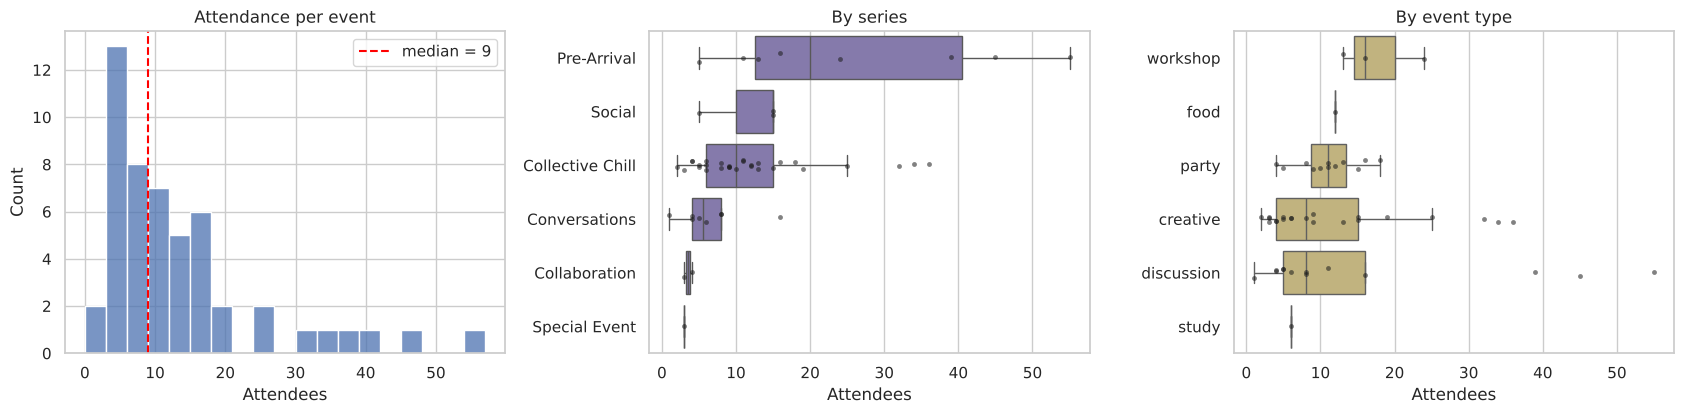

By series


,events,mean,median,max
Series,,,,
Pre-Arrival,8,26.0,20.0,55.0
Social,3,11.7,15.0,15.0
Collective Chill,29,12.4,10.0,36.0
Conversations,8,6.5,5.5,16.0
Collaboration,2,3.5,3.5,4.0
Special Event,1,3.0,3.0,3.0


By type


,events,mean,median,max
Type_event,,,,
workshop,3,17.7,16.0,24.0
food,1,12.0,12.0,12.0
party,12,11.0,11.0,18.0
creative,21,12.2,8.0,36.0
discussion,13,15.9,8.0,55.0
study,1,6.0,6.0,6.0


In [3]:
fig, ax = plt.subplots(1,3, figsize=(17,4.3))
sns.histplot(att['Number_Attendees'], bins=range(0,60,3), color='#4C72B0', ax=ax[0])
ax[0].axvline(att['Number_Attendees'].median(), color='red', ls='--', label=f"median = {att['Number_Attendees'].median():.0f}")
ax[0].set(title='Attendance per event', xlabel='Attendees'); ax[0].legend()

ser = att.groupby('Series')['Number_Attendees'].median().sort_values(ascending=False).index
sns.boxplot(data=att, y='Series', x='Number_Attendees', order=ser, color='#8172B3', ax=ax[1], showfliers=False)
sns.stripplot(data=att, y='Series', x='Number_Attendees', order=ser, color='k', size=3.5, alpha=.55, ax=ax[1])
ax[1].set(title='By series', xlabel='Attendees', ylabel='')

typ = att.groupby('Type_event')['Number_Attendees'].median().sort_values(ascending=False).index
sns.boxplot(data=att, y='Type_event', x='Number_Attendees', order=typ, color='#CCB974', ax=ax[2], showfliers=False)
sns.stripplot(data=att, y='Type_event', x='Number_Attendees', order=typ, color='k', size=3.5, alpha=.55, ax=ax[2])
ax[2].set(title='By event type', xlabel='Attendees', ylabel='')
plt.tight_layout(); plt.show()

def grp(col, d=att):
    return d.groupby(col)['Number_Attendees'].agg(events='count', mean='mean', median='median', max='max').round(1).sort_values('median', ascending=False)
print('By series'); display(grp('Series')); print('By type'); display(grp('Type_event'))

,Term,events,total,median,mean
0,Fall 2023,3,24.0,5.0,8.0
1,Winter 2024,9,94.0,12.0,10.4
2,Spring 2024,8,208.0,20.0,26.0
3,Fall 2024,9,72.0,6.0,8.0
4,Winter 2025,6,33.0,5.5,5.5
5,Spring 2025,2,12.0,6.0,6.0
6,Fall 2025,5,99.0,13.0,19.8
7,Winter 2026,5,77.0,9.0,15.4
8,Spring 2026,2,27.0,13.5,13.5
9,Fall 2026,2,20.0,10.0,10.0


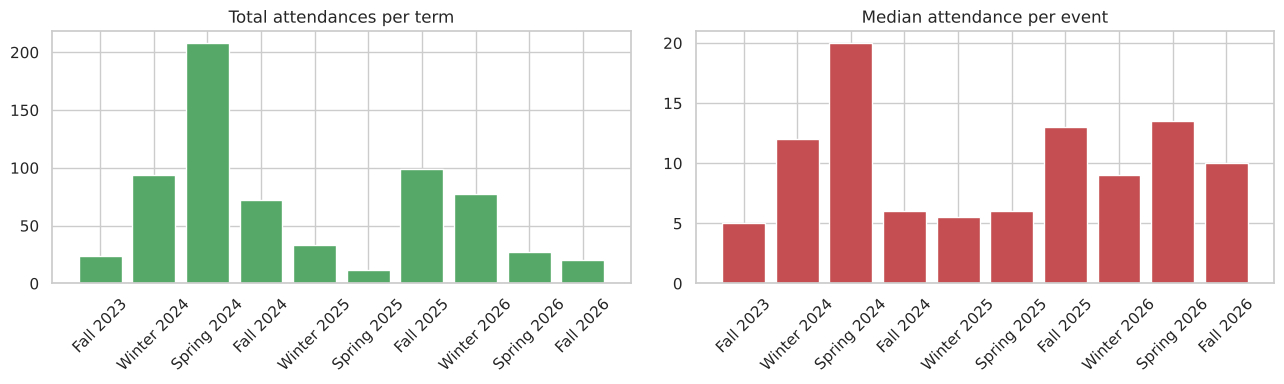

In [4]:
term = (att.groupby(['TermKey','Term'])['Number_Attendees'].agg(events='count', total='sum', median='median', mean='mean')
        .reset_index().sort_values('TermKey'))
display(term.drop(columns='TermKey').round(1))
fig, ax = plt.subplots(1,2, figsize=(13,4))
ax[0].bar(term['Term'], term['total'], color='#55A868'); ax[0].set_title('Total attendances per term')
ax[1].bar(term['Term'], term['median'], color='#C44E52'); ax[1].set_title('Median attendance per event')
for a in ax: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

In [5]:
print('In-person events only, by time of day and weekday (Pre-Arrival virtual sessions and hybrid removed so format does not distort timing):')
inp0 = att[att['Modality']=='In Person']
display(grp('Time', inp0))
dow = ['Monday','Tuesday','Wednesday','Thursday','Friday']
display(grp('Day_of_Week', inp0).reindex([d for d in dow if d in inp0['Day_of_Week'].values]))

In-person events only, by time of day and weekday (Pre-Arrival virtual sessions and hybrid removed so format does not distort timing):


,events,mean,median,max
Time,,,,
afternoon,18,14.3,12.0,36.0
evening,19,7.1,6.0,15.0


,events,mean,median,max
Day_of_Week,,,,
Monday,4,8.8,6.5,18.0
Tuesday,6,10.0,5.0,34.0
Wednesday,11,8.9,9.0,16.0
Thursday,14,13.0,8.5,36.0
Friday,6,10.7,11.0,19.0


**What I see (without Chill Spaces)**
- Dropping the 22 Chill Spaces sessions leaves 51 events with attendance. The median rises from 8 to 9, the mean from 11.3 to 13.1, and the share of events with 5 or fewer attendees falls from 34% to 29%.
- **Pre-Arrival** sessions are the largest (median 20, max 55), followed by **Collective Chill** (median 10) and the **Socials** (median 15, but only 3 events). **Conversations** (median 5.5) and **Collaboration** events with On Empathy (median 3.5, 2 events) are the smallest.
- By type, workshops (median 16, 3 events) and parties (median 11) are strongest. Creative events have a modest median (8) but produce the biggest in-person turnouts (up to 36), so they are the most variable.
- In person, **afternoon (median 12) beats evening (median 6)**. By weekday, Friday (11) and Wednesday (9) lead; Monday (6.5) and Tuesday (5) trail, though each weekday has only 4 to 14 events.
- Term totals swing with how many events were run: Spring 2024 (virtual Pre-Arrival) and Fall 2025 are the high points; Fall 2024 and Winter 2025 are the low points.

## 2. Food and attendance
**Defining "high attendance."** The median event in this analysis set is the natural dividing line: *high* = more attendees than the median, *low* = at or below it. (Section 2.4 checks that the conclusion doesn't depend on this cutoff.)

**Hypotheses**
- **H₀:** there is no association between food being offered and an event having high attendance.
- **H₁:** there is an association.

Tests used: **Fisher's exact test** as the primary test (cell counts are small, so the chi-square approximation is unreliable), with a chi-square test, a Mann-Whitney U test on the raw attendance counts, and a permutation test as cross-checks. α = 0.05.

In [6]:
MED = att['Number_Attendees'].median()
HIGH_CUT = int(np.floor(MED)) + 1          # 'high' means >= this many attendees
att['High'] = (att['Number_Attendees'] >= HIGH_CUT).astype(int)
print(f"Median = {MED:.0f}  →  high attendance = {HIGH_CUT}+ attendees")
print(f"High: {att['High'].sum()} of {len(att)} events ({att['High'].mean():.0%})")

food_known = att[att['Food_YN'].isin(['Yes','No'])].copy()
print(f"\nFood status unknown for {att['Food_YN'].isna().sum()} events (dropped from the food tests).")

print("\nFood by modality — look at the 'No' row:")
display(pd.crosstab(food_known['Food_YN'], food_known['Modality'], margins=True))

Median = 9  →  high attendance = 10+ attendees
High: 25 of 51 events (49%)

Food status unknown for 3 events (dropped from the food tests).

Food by modality — look at the 'No' row:


Modality,Hybrid,In Person,Virtual,All
Food_YN,,,,
No,0,9,8,17
Yes,2,29,0,31
All,2,38,8,48


**A confound to handle before testing.** Every virtual event had no food (food isn't served online). Virtual events were also all Pre-Arrival sessions for incoming students, which are the biggest events in the data. If we compare food vs no food across *all* events, the no-food group is contaminated by large virtual sessions, so any food effect would be tangled up with the virtual effect. I therefore run the test two ways: all events, and **in-person events only** (the fair comparison).

In [7]:
def food_tests(d, label, cut=None):
    cut = HIGH_CUT if cut is None else cut
    hi = (d['Number_Attendees']>=cut).astype(int)
    tab = pd.crosstab(d['Food_YN'], hi).reindex(index=['No','Yes'], columns=[0,1], fill_value=0)
    a_,b_ = tab.loc['Yes',1], tab.loc['Yes',0]     # food: high, low
    c_,d_ = tab.loc['No',1],  tab.loc['No',0]      # no food: high, low
    odds, p_fisher = stats.fisher_exact([[a_,b_],[c_,d_]])
    # Woolf CI with 0.5 continuity correction
    A,B,Cc,D = a_+.5,b_+.5,c_+.5,d_+.5
    se = np.sqrt(1/A+1/B+1/Cc+1/D); lo,hi_ = np.exp(np.log(A*D/(B*Cc)) + np.array([-1.96,1.96])*se)
    chi2, p_chi, _, _ = stats.chi2_contingency(tab, correction=False)
    y1 = d.loc[d['Food_YN']=='Yes','Number_Attendees']; y0 = d.loc[d['Food_YN']=='No','Number_Attendees']
    p_mwu = stats.mannwhitneyu(y1, y0, alternative='two-sided').pvalue
    # permutation test on difference in share high
    lab = (d['Food_YN']=='Yes').to_numpy(); h = hi.to_numpy(); obs = h[lab].mean()-h[~lab].mean()
    perm = np.array([ (lambda s: h[s].mean()-h[~s].mean())(rng.permutation(lab)) for _ in range(10000)])
    p_perm = (np.abs(perm)>=abs(obs)-1e-12).mean()
    return dict(sample=label, n=len(d), n_food=len(y1), n_nofood=len(y0),
                pct_high_food=a_/(a_+b_), pct_high_nofood=c_/(c_+d_),
                odds_ratio=odds, OR_95CI=f"{lo:.2f}–{hi_:.2f}", p_fisher=p_fisher, p_chi2=p_chi,
                p_mannwhitney=p_mwu, p_permutation=p_perm, median_food=y1.median(), median_nofood=y0.median())

res = pd.DataFrame([food_tests(food_known, 'All events'),
                    food_tests(food_known[food_known['Modality']=='In Person'], 'In-person only')]).set_index('sample')
display(res.T)

sample,All events,In-person only
n,48,38
n_food,31,29
n_nofood,17,9
pct_high_food,0.548387,0.551724
pct_high_nofood,0.411765,0.0
odds_ratio,1.734694,inf
OR_95CI,0.53–5.43,1.24–436.39
p_fisher,0.546873,0.004859
p_chi2,0.365258,0.003405
p_mannwhitney,0.721573,0.013854


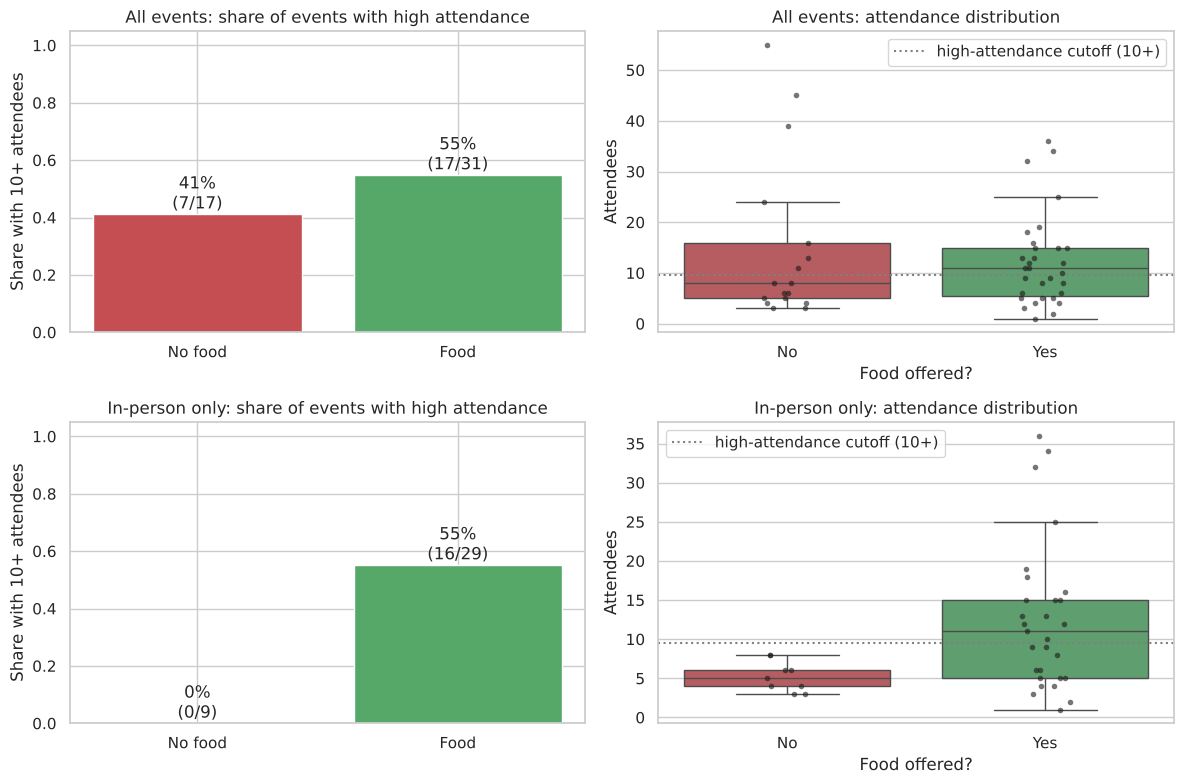

In [8]:
fig, axes = plt.subplots(2,2, figsize=(12,8))
samples = [('All events', food_known), ('In-person only', food_known[food_known['Modality']=='In Person'])]
for r,(name,d) in enumerate(samples):
    # share high
    g = d.groupby('Food_YN')['High'].agg(['mean','sum','count']).reindex(['No','Yes'])
    b = axes[r,0].bar(['No food','Food'], g['mean'], color=['#C44E52','#55A868'])
    for i,(m,s,c) in enumerate(zip(g['mean'], g['sum'], g['count'])):
        axes[r,0].text(i, m+.02, f"{m:.0%}\n({int(s)}/{int(c)})", ha='center')
    axes[r,0].set(ylim=(0,1.05), ylabel=f'Share with {HIGH_CUT}+ attendees', title=f'{name}: share of events with high attendance')
    # distribution
    sns.boxplot(data=d, x='Food_YN', y='Number_Attendees', order=['No','Yes'], palette=['#C44E52','#55A868'], showfliers=False, ax=axes[r,1])
    sns.stripplot(data=d, x='Food_YN', y='Number_Attendees', order=['No','Yes'], color='k', size=4, alpha=.6, ax=axes[r,1])
    axes[r,1].axhline(HIGH_CUT-0.5, color='gray', ls=':', label=f'high-attendance cutoff ({HIGH_CUT}+)'); axes[r,1].legend()
    axes[r,1].set(title=f'{name}: attendance distribution', xlabel='Food offered?', ylabel='Attendees')
plt.tight_layout(); plt.show()

**Result: reject H₀ for in-person events; no evidence of an association when virtual events are included.**
- **In-person events:** none of the 9 no-food events reached 10+ attendees, compared with 16 of 29 (55%) food events. Fisher's exact p = 0.005 (chi-square 0.003, Mann-Whitney 0.014, permutation 0.006), so all four tests agree. Median attendance was 11 with food and 5 without. The odds ratio is undefined because one cell is zero (the interval is enormous), so I would quote the percentages rather than an odds ratio.
- **All events pooled:** 55% vs 41% high, p = 0.55. This is not a contradiction: the 8 virtual events all had no food and were mostly large, so they hide the effect. This is why the in-person comparison is the fair one.

### 2.3 Is food just standing in for event type?
If food tends to go with certain event types, the type could be the real driver. Let's check.

Counts of in-person events: type × food


Food_YN,No,Yes,All
Type_event,,,
creative,6,14,20
discussion,3,3,6
food,0,1,1
party,0,10,10
study,0,1,1
All,9,29,38


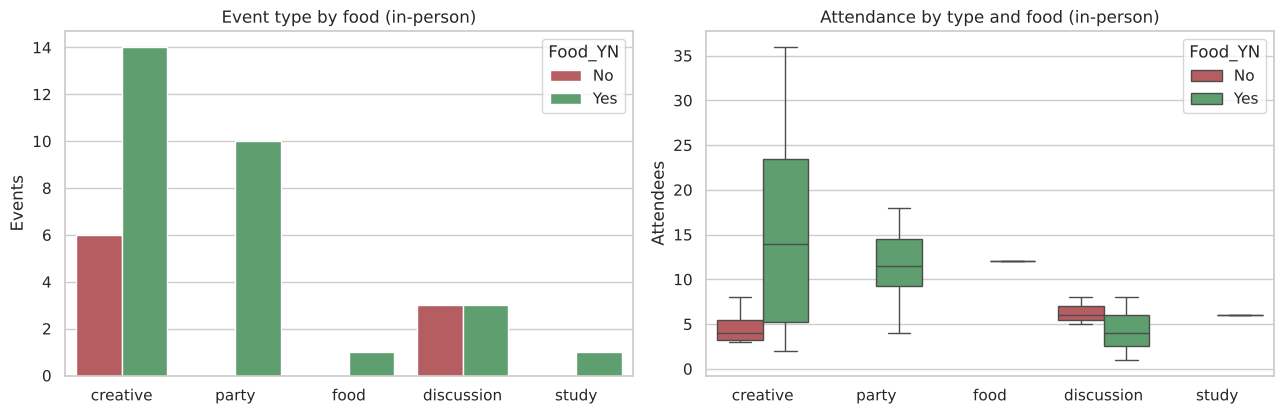

Same comparison, restricted to creative events (the largest type):


,count,mean,median
Food_YN,,,
No,6,4.7,4.0
Yes,14,15.6,14.0


Fisher p (high vs food, creative only): 0.042


In [9]:
inp = food_known[food_known['Modality']=='In Person'].copy()
print('Counts of in-person events: type × food'); display(pd.crosstab(inp['Type_event'], inp['Food_YN'], margins=True))

fig, ax = plt.subplots(1,2, figsize=(13,4.3))
sns.countplot(data=inp, x='Type_event', hue='Food_YN', hue_order=['No','Yes'], palette=['#C44E52','#55A868'], ax=ax[0])
ax[0].set(title='Event type by food (in-person)', xlabel='', ylabel='Events')
sns.boxplot(data=inp, x='Type_event', y='Number_Attendees', hue='Food_YN', hue_order=['No','Yes'],
            palette=['#C44E52','#55A868'], showfliers=False, ax=ax[1])
ax[1].set(title='Attendance by type and food (in-person)', xlabel='', ylabel='Attendees')
plt.tight_layout(); plt.show()

print('Same comparison, restricted to creative events (the largest type):')
cr = inp[inp['Type_event']=='creative']
display(cr.groupby('Food_YN')['Number_Attendees'].agg(['count','mean','median']).round(1))
if cr['Food_YN'].nunique()==2:
    print('Fisher p (high vs food, creative only):', round(stats.fisher_exact(pd.crosstab(cr['Food_YN'], cr['High']).reindex(index=['No','Yes'],columns=[0,1],fill_value=0))[1],3))

### 2.4 Does the answer depend on where I draw the 'high' line?

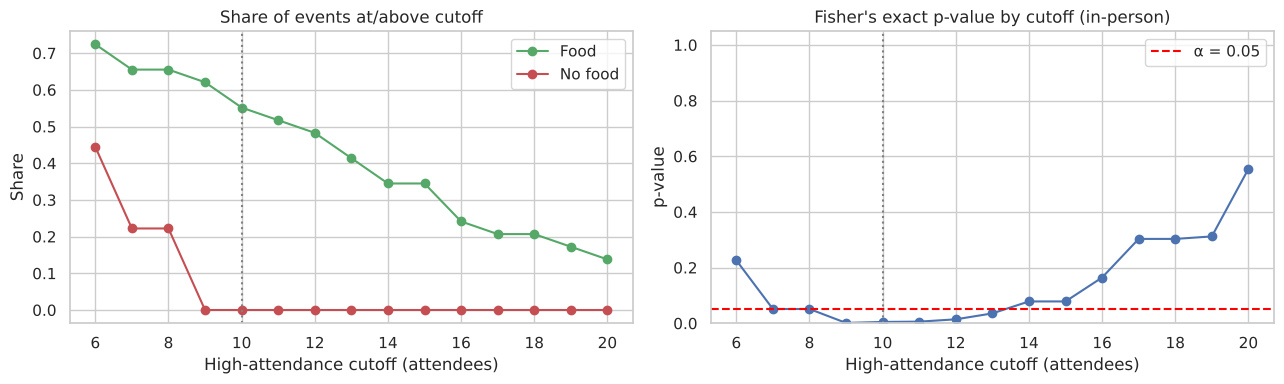

cutoff,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
pct_high_food,0.724,0.655,0.655,0.621,0.552,0.517,0.483,0.414,0.345,0.345,0.241,0.207,0.207,0.172,0.138
pct_high_nofood,0.444,0.222,0.222,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
p_fisher,0.226,0.051,0.051,0.001,0.005,0.006,0.014,0.036,0.079,0.079,0.164,0.303,0.303,0.312,0.554
odds_ratio,3.281,6.650,6.650,inf,inf,inf,inf,inf,inf,inf,inf,inf,inf,inf,inf


In [10]:
rows=[]
ip = food_known[food_known['Modality']=='In Person']
for cut in range(6, 21):
    t = food_tests(ip, 'in-person', cut=cut)
    rows.append(dict(cutoff=cut, pct_high_food=t['pct_high_food'], pct_high_nofood=t['pct_high_nofood'],
                     p_fisher=t['p_fisher'], odds_ratio=t['odds_ratio']))
sens = pd.DataFrame(rows)
fig, ax = plt.subplots(1,2, figsize=(13,4))
ax[0].plot(sens['cutoff'], sens['pct_high_food'], marker='o', color='#55A868', label='Food')
ax[0].plot(sens['cutoff'], sens['pct_high_nofood'], marker='o', color='#C44E52', label='No food')
ax[0].axvline(HIGH_CUT, color='gray', ls=':'); ax[0].set(title='Share of events at/above cutoff', xlabel='High-attendance cutoff (attendees)', ylabel='Share'); ax[0].legend()
ax[1].plot(sens['cutoff'], sens['p_fisher'], marker='o', color='#4C72B0')
ax[1].axhline(.05, color='red', ls='--', label='α = 0.05'); ax[1].axvline(HIGH_CUT, color='gray', ls=':')
ax[1].set(title="Fisher's exact p-value by cutoff (in-person)", xlabel='High-attendance cutoff (attendees)', ylabel='p-value', ylim=(0,1.05)); ax[1].legend()
plt.tight_layout(); plt.show()
display(sens.round(3).set_index('cutoff').T)

**How far to trust the food result**
- **It holds within creative events** (the biggest type): median 14 with food (14 events) vs 4 without (6 events), Fisher p = 0.042. That is a small sample and one of several looks I took, so treat it as supporting evidence rather than proof. Parties always had food (10 of 10), so type and food overlap.
- **It survives most reasonable cutoffs.** The p-value is below 0.05 for cutoffs of 9 to 13 attendees and is borderline (0.051) at 7 to 8. It is not significant at 14 or more (very few events are that large, so the test has no power) or at 6. No no-food in-person event ever exceeded 8 attendees. I fixed the cutoff at the median (10) before testing rather than picking the best-looking one.
- **Food is tangled up with other things.** Of the 9 no-food events, 7 were evening events, 8 ran in 2023–24 (the program's early period), and 2 were off-campus collaborations. Evening, early-program, and off-campus events all drew fewer people for reasons unrelated to food. The data cannot fully separate those from food, and food may also mark events that got more budget and planning.

## 3. Virtual vs in-person vs hybrid

,events,mean,median,min,max,series,pct_food
Modality,,,,,,,
Hybrid,2,9.50,9.5,8.0,11.0,Collective Chill,1.00
In Person,41,10.71,8.0,1.0,36.0,"Collaboration, Collective Chill, Conversations, Social, ...",0.76
Virtual,8,26.00,20.0,5.0,55.0,Pre-Arrival,0.00


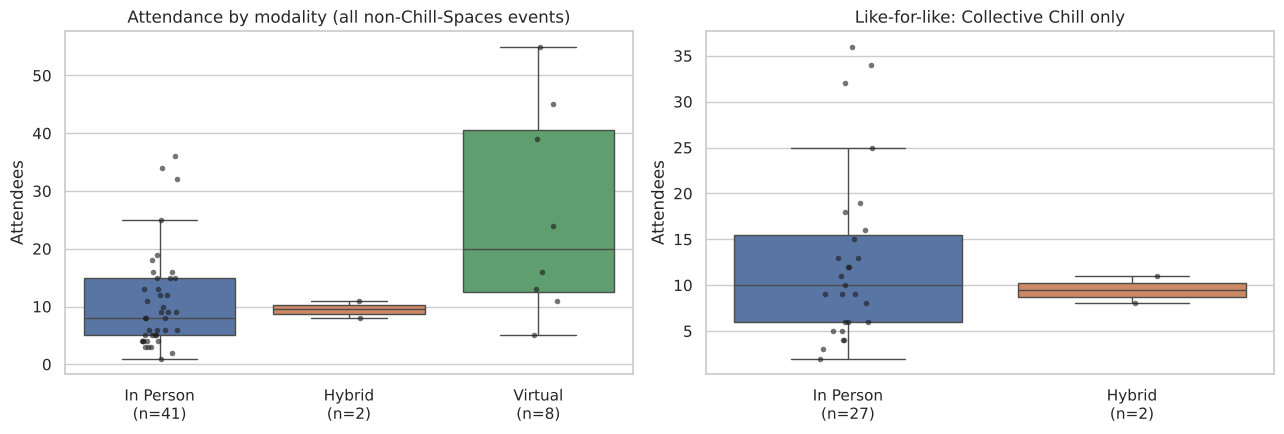

In [11]:
mod = att.groupby('Modality').agg(events=('Number_Attendees','count'), mean=('Number_Attendees','mean'),
        median=('Number_Attendees','median'), min=('Number_Attendees','min'), max=('Number_Attendees','max'),
        series=('Series', lambda s: ', '.join(sorted(s.unique()))),
        pct_food=('Food_YN', lambda s: (s=='Yes').sum()/s.notna().sum() if s.notna().sum() else np.nan)).round(2)
display(mod)

fig, ax = plt.subplots(1,2, figsize=(13,4.5))
mo = ['In Person','Hybrid','Virtual']; pal = ['#4C72B0','#DD8452','#55A868']
sns.boxplot(data=att, x='Modality', y='Number_Attendees', order=mo, palette=pal, showfliers=False, ax=ax[0])
sns.stripplot(data=att, x='Modality', y='Number_Attendees', order=mo, color='k', size=4, alpha=.6, ax=ax[0])
ax[0].set(title='Attendance by modality (all non-Chill-Spaces events)', xlabel='', ylabel='Attendees')
ax[0].set_xticklabels([f"{m}\n(n={int((att['Modality']==m).sum())})" for m in mo])

# Like-for-like: Collective Chill only, in-person vs hybrid
chill = att[att['Series']=='Collective Chill']
sns.boxplot(data=chill, x='Modality', y='Number_Attendees', order=['In Person','Hybrid'], palette=['#4C72B0','#DD8452'], showfliers=False, ax=ax[1])
sns.stripplot(data=chill, x='Modality', y='Number_Attendees', order=['In Person','Hybrid'], color='k', size=4, alpha=.6, ax=ax[1])
ax[1].set(title='Like-for-like: Collective Chill only', xlabel='', ylabel='Attendees')
ax[1].set_xticklabels([f"{m}\n(n={int((chill['Modality']==m).sum())})" for m in ['In Person','Hybrid']])
plt.tight_layout(); plt.show()

In [12]:
print('Cross-tab: modality × series — virtual events are ALL Pre-Arrival, so format and audience cannot be separated.')
display(pd.crosstab(att['Series'], att['Modality'], margins=True))

print('\nThe virtual events, in date order:')
v = att[att['Modality']=='Virtual'].sort_values('Date')
display(v[['Date','Event_Name','Number_Attendees','Limit']].assign(Event_Name=lambda d: d['Event_Name'].str.slice(0,70)).reset_index(drop=True))

print('\nThe hybrid events:')
display(att[att['Modality']=='Hybrid'][['Date','Event_Name','Number_Attendees','Limit','Attendance_Factors']].assign(Event_Name=lambda d: d['Event_Name'].str.slice(0,50)))

Cross-tab: modality × series — virtual events are ALL Pre-Arrival, so format and audience cannot be separated.


Modality,Hybrid,In Person,Virtual,All
Series,,,,
Collaboration,0,2,0,2
Collective Chill,2,27,0,29
Conversations,0,8,0,8
Pre-Arrival,0,0,8,8
Social,0,3,0,3
Special Event,0,1,0,1
All,2,41,8,51



The virtual events, in date order:


,Date,Event_Name,Number_Attendees,Limit
0,2024-07-23,"""Connection Collective Kick-off: Meet & Greet - In this ...",55.0,NaN
1,2024-07-29,Family & Supporter Information Session: Equity and Commu...,5.0,NaN
2,2024-08-01,Student Clubs & Services: Human Library Info Session - I...,39.0,100.0
3,2024-08-02,Campus Compass: Navigating University Life with Confiden...,24.0,25.0
4,2024-08-06,"Student, Faculty, and Community Roundtable on Belonging ...",45.0,100.0
5,2024-08-07,I JUST GOT HERE!,16.0,NaN
6,2024-08-08,Haldimand Tract Welcome With David Moses - The Connectio...,11.0,NaN
7,2024-08-16,Expectations vs Realities: University Edition,13.0,NaN



The hybrid events:


,Date,Event_Name,Number_Attendees,Limit,Attendance_Factors
36,2025-04-02,Celebrate Connection Collective (Collective Chill),8.0,NaN,Hybrid format; most participants engaged with the virtua...
41,2025-11-05,Gam-o-clock: Cozy Games & Good Vibes,11.0,30.0,NaN


In [13]:
vi = att.loc[att['Modality']=='Virtual','Number_Attendees']; ip_ = att.loc[att['Modality']=='In Person','Number_Attendees']
ip_pre = att[(att['Modality']=='In Person')]
print(f"Virtual (n={len(vi)}) vs in-person (n={len(ip_)}):")
u = stats.mannwhitneyu(vi, ip_, alternative='two-sided'); print(f"  Mann-Whitney U p = {u.pvalue:.4f}   (medians {vi.median():.0f} vs {ip_.median():.1f})")
# effect size: probability a random virtual event beats a random in-person event
print(f"  P(random virtual event > random in-person event) = {u.statistic/(len(vi)*len(ip_)):.2f}")
hy = chill.loc[chill['Modality']=='Hybrid','Number_Attendees']; ic = chill.loc[chill['Modality']=='In Person','Number_Attendees']
print(f"\nHybrid (n={len(hy)}) vs in-person Collective Chill (n={len(ic)}): medians {hy.median():.1f} vs {ic.median():.1f}  — n=2 is too small for a test.")
print(f"\nShare of events reaching {HIGH_CUT}+ attendees:  virtual {(vi>=HIGH_CUT).mean():.0%}   hybrid {(att.loc[att['Modality']=='Hybrid','Number_Attendees']>=HIGH_CUT).mean():.0%}   in-person {(ip_>=HIGH_CUT).mean():.0%}")

Virtual (n=8) vs in-person (n=41):
  Mann-Whitney U p = 0.0093   (medians 20 vs 8.0)
  P(random virtual event > random in-person event) = 0.79

Hybrid (n=2) vs in-person Collective Chill (n=27): medians 9.5 vs 10.0  — n=2 is too small for a test.

Share of events reaching 10+ attendees:  virtual 88%   hybrid 50%   in-person 41%


**What I see**
- **Virtual events were larger:** median 20 vs 8 for in-person (Mann-Whitney p = 0.009), and 7 of 8 virtual events reached 10+ attendees vs 41% of in-person events.
- **But I would not read this as "virtual works better."** All 8 virtual events are Pre-Arrival sessions for incoming students, run in summer 2024, with no virtual events in any other series. The comparison is really "Pre-Arrival audience vs everyone else," and format cannot be separated from audience.
- Within the virtual group, the kickoff (55) and the belonging roundtable (45) were largest, while the family and supporter session drew only 5.
- **Hybrid** (2 events, 8 and 11 attendees) looks the same as in-person Collective Chill (median 9.5 vs 10). Two events is too few to say anything beyond that. The Leads noted that hybrid attendees engaged mostly with the virtual games.
- To learn whether virtual helps for regular programming, a few virtual or hybrid events in a non-Pre-Arrival series would be needed.

## 4. Modeling the categorical features (drop-in events excluded)
**Goal:** see which categorical features (event type, time of day, weekday, food, format) are associated with *high attendance*, and whether they predict it at all.

**Approach.** The outcome is binary (high = 10+ attendees, same as Section 2). With only ~50 events and many sparse categories, an ordinary logistic regression would produce unstable or infinite coefficients (separation), so I use:
1. **Bivariate association tests** for each feature (chi-square with a permutation p-value, plus Cramér's V for effect size)
2. **Ridge (L2-penalized) logistic regression** on one-hot features, evaluated with **leave-one-out cross-validation**, and compared to a "no information" baseline
3. A **permutation test** on the cross-validated AUC to check whether the model beats chance
4. **Bootstrap confidence intervals** on the odds ratios
5. A shallow **decision tree** as a human-readable cross-check

The primary model uses **in-person events only**, because virtual/Pre-Arrival is perfectly tangled with 'morning', 'no food' and 'Pre-Arrival' (Section 3). A second model adds format back in as a sensitivity check.

In [14]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.tree import DecisionTreeClassifier, export_text

m = att.copy()
m['Type_grp'] = m['Type_event'].replace({'workshop':'workshop/other','food':'workshop/other','study':'workshop/other'})
for c in ['Time','Food_YN']: m[c] = m[c].fillna('unknown')
m = m.rename(columns={'Type_grp':'Type','Day_of_Week':'Weekday','Food_YN':'Food','Time':'TimeOfDay'})
CATS = ['Type','TimeOfDay','Weekday','Food']

inperson = m[m['Modality']=='In Person'].copy()
print(f"Modeling set (in-person, no Chill Spaces, attendance known): n = {len(inperson)},  high = {inperson['High'].sum()} ({inperson['High'].mean():.0%})")
for c in CATS: print(f"  {c}: {inperson[c].value_counts().to_dict()}")

Modeling set (in-person, no Chill Spaces, attendance known): n = 41,  high = 17 (41%)
  Type: {'creative': 21, 'party': 10, 'discussion': 8, 'workshop/other': 2}
  TimeOfDay: {'evening': 19, 'afternoon': 18, 'unknown': 4}
  Weekday: {'Thursday': 14, 'Wednesday': 11, 'Tuesday': 6, 'Friday': 6, 'Monday': 4}
  Food: {'Yes': 29, 'No': 9, 'unknown': 3}


,chi2,perm_p,cramers_V,levels
feature,,,,
Type,6.278,0.085,0.391,creative: 38% (n=21); discussion: 12% (n=8); party: 70% ...
TimeOfDay,3.389,0.197,0.288,afternoon: 56% (n=18); evening: 26% (n=19); unknown: 50%...
Weekday,3.620,0.480,0.297,Friday: 67% (n=6); Monday: 25% (n=4); Thursday: 43% (n=1...
Food,8.702,0.008,0.461,No: 0% (n=9); Yes: 55% (n=29); unknown: 33% (n=3)


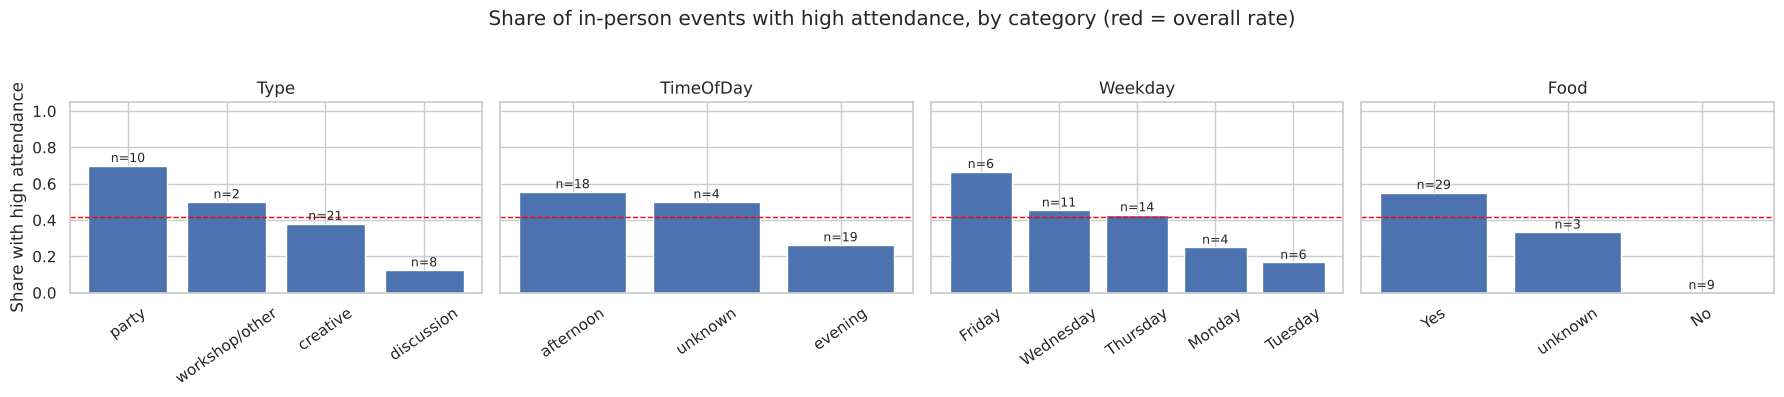

In [15]:
# 4.1 bivariate association with high attendance
def perm_chi2(x, y, n=5000):
    tab = pd.crosstab(x, y); obs = stats.chi2_contingency(tab, correction=False)[0]
    ys = y.to_numpy(); xs = x.to_numpy(); cnt = 0
    for _ in range(n):
        t = pd.crosstab(xs, rng.permutation(ys)); cnt += stats.chi2_contingency(t, correction=False)[0] >= obs-1e-9
    cramer = np.sqrt(obs/(tab.values.sum()*(min(tab.shape)-1)))
    return obs, (cnt+1)/(n+1), cramer

rows=[]
for c in CATS:
    chi, p, v = perm_chi2(inperson[c], inperson['High'])
    lv = inperson.groupby(c)['High'].agg(['mean','count'])
    rows.append(dict(feature=c, chi2=chi, perm_p=p, cramers_V=v,
                     levels='; '.join(f"{i}: {r['mean']:.0%} (n={int(r['count'])})" for i,r in lv.iterrows())))
assoc = pd.DataFrame(rows).set_index('feature'); display(assoc.round(3))

fig, axes = plt.subplots(1,4, figsize=(18,3.8), sharey=True)
for ax_,c in zip(axes, CATS):
    g = inperson.groupby(c)['High'].agg(['mean','count']).sort_values('mean', ascending=False)
    ax_.bar(g.index.astype(str), g['mean'], color='#4C72B0')
    for i,(mu,n) in enumerate(zip(g['mean'], g['count'])): ax_.text(i, mu+.02, f"n={n}", ha='center', fontsize=9)
    ax_.axhline(inperson['High'].mean(), color='red', ls='--', lw=1)
    ax_.set_title(c); ax_.tick_params(axis='x', rotation=35)
axes[0].set_ylabel('Share with high attendance'); axes[0].set_ylim(0,1.05)
plt.suptitle('Share of in-person events with high attendance, by category (red = overall rate)', y=1.04); plt.tight_layout(); plt.show()

In [16]:
# 4.2 Ridge logistic regression with leave-one-out CV
def make_model(C, cats):
    pre = ColumnTransformer([('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cats)])
    return make_pipeline(pre, LogisticRegression(C=C, penalty='l2', max_iter=2000))

def loo_eval(d, cats, C):
    X, y = d[cats], d['High'].to_numpy()
    p = cross_val_predict(make_model(C,cats), X, y, cv=LeaveOneOut(), method='predict_proba')[:,1]
    return p, y

d = inperson
grid = []
for C in [0.05,0.1,0.25,0.5,1,2,5]:
    p,y = loo_eval(d, CATS, C); grid.append(dict(C=C, LOO_AUC=roc_auc_score(y,p), LOO_Brier=brier_score_loss(y,p)))
grid = pd.DataFrame(grid).set_index('C'); display(grid.round(3))
BASE_BRIER = brier_score_loss(d['High'], np.full(len(d), d['High'].mean()))
print(f"Baseline (predict the overall high-rate for every event): Brier = {BASE_BRIER:.3f}, AUC = 0.50")

,LOO_AUC,LOO_Brier
C,,
0.05,0.593,0.239
0.10,0.642,0.231
0.25,0.662,0.224
0.50,0.669,0.223
1.00,0.664,0.227
2.00,0.642,0.236
5.00,0.647,0.253


Baseline (predict the overall high-rate for every event): Brier = 0.243, AUC = 0.50


Chosen C = 0.5.  LOO AUC = 0.669,  LOO accuracy = 63%  (always-guess-majority accuracy = 59%),  Brier = 0.223 vs baseline 0.243


Permutation test on LOO AUC: p = 0.040   (null AUCs: mean 0.41, 95th pct 0.65)


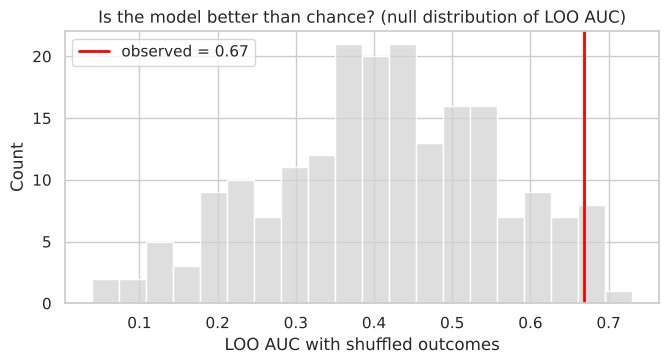

In [17]:
bestC = grid['LOO_AUC'].idxmax()
p, y = loo_eval(d, CATS, bestC)
auc_obs = roc_auc_score(y, p)
acc = ((p>=.5)==y).mean(); base_acc = max(y.mean(), 1-y.mean())
print(f"Chosen C = {bestC}.  LOO AUC = {auc_obs:.3f},  LOO accuracy = {acc:.0%}  (always-guess-majority accuracy = {base_acc:.0%}),  Brier = {brier_score_loss(y,p):.3f} vs baseline {BASE_BRIER:.3f}")

# Does the model beat chance? Permute outcome labels and redo the whole LOO evaluation.
perm_auc = []
for _ in range(200):
    yp = rng.permutation(y); dd = d.copy(); dd['High'] = yp
    pp,_ = loo_eval(dd, CATS, bestC); perm_auc.append(roc_auc_score(yp, pp))
perm_auc = np.array(perm_auc); p_auc = (np.sum(perm_auc >= auc_obs)+1)/(len(perm_auc)+1)
print(f"Permutation test on LOO AUC: p = {p_auc:.3f}   (null AUCs: mean {perm_auc.mean():.2f}, 95th pct {np.percentile(perm_auc,95):.2f})")

plt.figure(figsize=(7,3.8)); sns.histplot(perm_auc, bins=20, color='lightgray'); plt.axvline(auc_obs, color='red', lw=2, label=f'observed = {auc_obs:.2f}')
plt.title('Is the model better than chance? (null distribution of LOO AUC)'); plt.xlabel('LOO AUC with shuffled outcomes'); plt.legend(); plt.tight_layout(); plt.show()

,odds_ratio,lo95,hi95,CI_excludes_1
Food_No,0.50,0.38,0.69,True
Type_discussion,0.64,0.44,1.01,False
TimeOfDay_evening,0.64,0.40,1.05,False
Weekday_Monday,0.74,0.50,1.18,False
Weekday_Tuesday,0.76,0.52,1.24,False
Weekday_Wednesday,0.95,0.51,1.74,False
Type_workshop/other,0.96,0.65,1.41,False
Type_creative,0.97,0.57,1.59,False
Food_unknown,1.04,0.74,1.54,False
Weekday_Thursday,1.21,0.69,1.99,False


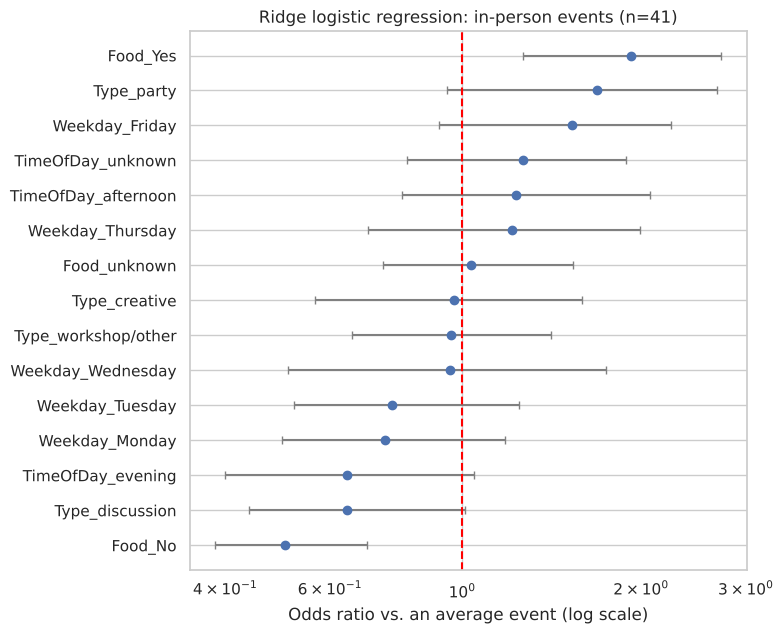

In [18]:
# 4.3 Odds ratios with bootstrap CIs
def fit_or(dfit, cats, C):
    mdl = make_model(C, cats).fit(dfit[cats], dfit['High'])
    names = mdl[0].get_feature_names_out(); coefs = mdl[-1].coef_[0]
    return pd.Series(np.exp(coefs), index=[n.replace('oh__','') for n in names])

point = fit_or(d, CATS, bestC)
boots = []
for _ in range(1000):
    s = d.sample(len(d), replace=True, random_state=int(rng.integers(1e9)))
    if s['High'].nunique()==2: boots.append(fit_or(s, CATS, bestC).reindex(point.index))
boots = pd.DataFrame(boots)
orr = pd.DataFrame({'odds_ratio':point, 'lo95':boots.quantile(.025), 'hi95':boots.quantile(.975)}).sort_values('odds_ratio')
orr['CI_excludes_1'] = (orr['lo95']>1)|(orr['hi95']<1)
display(orr.round(2))

fig, ax = plt.subplots(figsize=(8,6.5))
y_ = np.arange(len(orr))
ax.errorbar(orr['odds_ratio'], y_, xerr=[orr['odds_ratio']-orr['lo95'], orr['hi95']-orr['odds_ratio']], fmt='o', color='#4C72B0', ecolor='gray', capsize=3)
ax.axvline(1, color='red', ls='--'); ax.set_yticks(y_); ax.set_yticklabels(orr.index); ax.set_xscale('log')
ax.set(xlabel='Odds ratio vs. an average event (log scale)', title=f'Ridge logistic regression: in-person events (n={len(d)})')
plt.tight_layout(); plt.show()

In [19]:
# 4.4 Sensitivity: add format (virtual / hybrid) back in; and a plain decision tree
m_all = m.copy()
CATS_ALL = ['Type','TimeOfDay','Weekday','Food','Modality']
gridA = []
for C in [0.1,0.25,0.5,1,2]:
    pA,yA = loo_eval(m_all, CATS_ALL, C); gridA.append(dict(C=C, LOO_AUC=roc_auc_score(yA,pA)))
gridA = pd.DataFrame(gridA).set_index('C'); bestCA = gridA['LOO_AUC'].idxmax()
print(f"All non-drop-in events (n={len(m_all)}, incl. virtual/hybrid) with Modality added: best LOO AUC = {gridA['LOO_AUC'].max():.3f} at C={bestCA}")
pointA = fit_or(m_all, CATS_ALL, bestCA).sort_values()
print('\nLargest effects in this version (odds ratios):'); display(pd.concat([pointA.head(4), pointA.tail(4)]).round(2).to_frame('odds_ratio'))

print('\nDecision tree (depth 2) on in-person events:')
Xd = pd.get_dummies(d[CATS]).astype(int)
tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=4, random_state=0).fit(Xd, d['High'])
print(export_text(tree, feature_names=list(Xd.columns), show_weights=True))
pt = cross_val_predict(DecisionTreeClassifier(max_depth=2, min_samples_leaf=4, random_state=0), Xd, d['High'], cv=LeaveOneOut(), method='predict_proba')[:,1]
print(f"Tree LOO AUC = {roc_auc_score(d['High'], pt):.3f}")

All non-drop-in events (n=51, incl. virtual/hybrid) with Modality added: best LOO AUC = 0.729 at C=1.0

Largest effects in this version (odds ratios):


,odds_ratio
TimeOfDay_evening,0.36
Modality_In Person,0.46
Weekday_Monday,0.52
Type_discussion,0.59
Food_Yes,1.89
Weekday_Friday,1.94
TimeOfDay_morning,2.16
Modality_Virtual,3.06



Decision tree (depth 2) on in-person events:
|--- Food_No <= 0.50
|   |--- Weekday_Friday <= 0.50
|   |   |--- weights: [15.00, 13.00] class: 0
|   |--- Weekday_Friday >  0.50
|   |   |--- weights: [0.00, 4.00] class: 1
|--- Food_No >  0.50
|   |--- weights: [9.00, 0.00] class: 0

Tree LOO AUC = 0.511


**What the model says**
- **Food is the only feature with a clear signal.** It is the only one with a significant bivariate association (permutation p = 0.008, Cramér's V = 0.46). Event type is borderline (p = 0.085); time of day (0.20) and weekday (0.48) are not significant.
- **The model has real but modest predictive power.** Leave-one-out AUC is 0.67 (0.5 is chance) and accuracy is 63% vs 59% for always guessing the majority. The permutation test on AUC gives p = 0.040, but that test did not account for the tuning of C, so treat it as borderline.
- **Odds ratios (vs an average event):** Food is the only one whose bootstrap interval excludes 1 (food: 1.9, no food: 0.5). Suggestive but not conclusive: parties 1.7 (interval 0.9–2.7), discussion events 0.6 and evening events 0.6 (intervals reach just above 1), Friday 1.5. Weekday effects are otherwise indistinguishable from noise.
- **Adding format back in** (all 51 non-drop-in events) lifts the AUC to 0.73. Virtual is associated with higher attendance (odds ratio about 3), and the evening penalty gets stronger (about 0.36). Those effects are driven by the Pre-Arrival confound from Section 3, so they are not independent findings.
- **The decision tree does not generalize.** It splits on food first (the same 9 events), then Friday, but its cross-validated AUC is 0.51, which is chance. That is a useful reminder that the whole food signal rests on 9 events.

**Bottom line:** among regular in-person events, food is the strongest associated factor, with afternoon timing and party/creative formats pointing in the same direction, but with about 40 events none of this is strong enough to treat as settled.

## Caveats that apply to everything above
- **Small samples.** There are about 40 in-person events and 8 virtual ones; many comparisons rest on groups of under 10.
- **Observational data.** Associations aren't causes: event type, term, promotion, and timing all move together.
- **Missing values** (food, time) are mostly 2026 headcount-log rows; they were dropped from the food tests and treated as an 'unknown' category in the model.
- **Multiple comparisons.** I looked at several features; a single p ≈ 0.04 among many would not be convincing on its own.